# 05 — Testes estatísticos e intervalos de confiança

Análise das diferenças de inadimplência entre os segmentos do K-Means e da distribuição do limite de crédito. Os testes são exploratórios e usam apenas o conjunto de treino exportado no notebook 02.

## 1. Configuração

Usamos o arquivo de segmentos gerado no notebook 02. Execute aquele notebook antes deste caso o CSV ainda não exista.

In [8]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
N_BOOTSTRAP = 2000

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

ARQUIVO = ROOT / "data" / "processed" / "segmentos_treino.csv"
FIGURAS = ROOT / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

if not ARQUIVO.exists():
    raise FileNotFoundError(
        "Arquivo de segmentos não encontrado. Execute o notebook 02 e salve suas exportações."
    )

df = pd.read_csv(ARQUIVO)
necessarias = {"segmento", "inadimplente", "limite_credito"}
assert necessarias.issubset(df.columns)
assert df["inadimplente"].isin([0, 1]).all()
assert df[list(necessarias)].notna().all().all()

print("Registros:", len(df))
print("Segmentos:", sorted(df["segmento"].unique().tolist()))
print("Taxa geral de inadimplência:", f"{df['inadimplente'].mean():.2%}")

Registros: 24000
Segmentos: [0, 1, 2]
Taxa geral de inadimplência: 22.12%


## 2. Taxa de inadimplência por segmento

A primeira comparação é descritiva: tamanho dos segmentos, inadimplentes observados e taxas. O K-Means foi treinado sem a variável de inadimplência.

,segmento,clientes,inadimplentes,taxa,taxa_pct
0,0,1335,411,0.307865,30.79
1,1,17489,2266,0.129567,12.96
2,2,5176,2632,0.508501,50.85


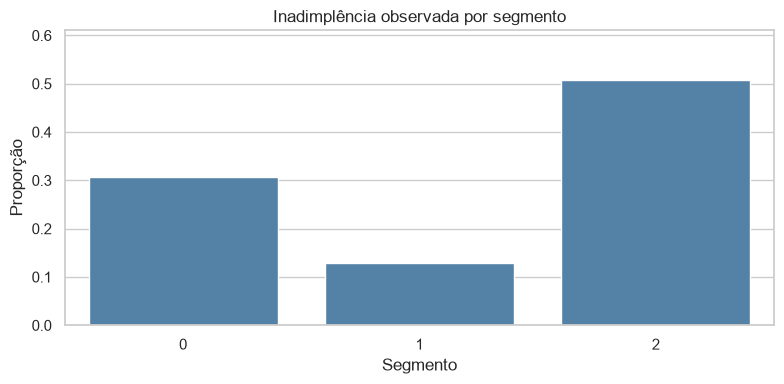

In [9]:
resumo = (
    df.groupby("segmento")["inadimplente"]
      .agg(clientes="size", inadimplentes="sum", taxa="mean")
      .reset_index()
      .sort_values("segmento")
)

display(resumo.assign(taxa_pct=(resumo["taxa"] * 100).round(2)))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=resumo, x="segmento", y="taxa", color="steelblue", ax=ax)
ax.set(title="Inadimplência observada por segmento", xlabel="Segmento", ylabel="Proporção")
ax.set_ylim(0, max(0.1, resumo["taxa"].max() * 1.2))
plt.tight_layout()
plt.savefig(FIGURAS / "05_taxas_segmentos.png", dpi=140)
plt.show()

## 3. Teste qui-quadrado

**H0:** a inadimplência é independente do segmento. **H1:** existe associação entre segmento e inadimplência.

Usamos nível de significância de 5%. Também calculamos o V de Cramér para descrever a intensidade da associação. Como os segmentos foram definidos com variáveis relacionadas ao risco, esse teste deve ser lido como uma análise exploratória, não como validação causal.

In [10]:
contingencia = pd.crosstab(df["segmento"], df["inadimplente"])
contingencia = contingencia.reindex(columns=[0, 1], fill_value=0)

chi2, p_valor, graus_liberdade, esperados = chi2_contingency(contingencia)
n_total = contingencia.to_numpy().sum()
v_cramer = np.sqrt(chi2 / (n_total * min(contingencia.shape[0] - 1, contingencia.shape[1] - 1)))

print("Tabela de contingência:")
display(contingencia)
print(f"Qui-quadrado: {chi2:.4f}")
print(f"Graus de liberdade: {graus_liberdade}")
print(f"p-valor: {p_valor:.3e}")
print(f"V de Cramér: {v_cramer:.4f}")
print(f"Menor frequência esperada: {esperados.min():.2f}")

if esperados.min() < 5:
    print("Atenção: há frequências esperadas abaixo de 5; avalie outro teste.")
print("Resultado (5%):", "rejeitamos H0" if p_valor < 0.05 else "não rejeitamos H0")

Tabela de contingência:


inadimplente,0,1
segmento,,
0,924,411
1,15223,2266
2,2544,2632


Qui-quadrado: 3390.5677
Graus de liberdade: 2
p-valor: 0.000e+00
V de Cramér: 0.3759
Menor frequência esperada: 295.31
Resultado (5%): rejeitamos H0


## 4. Bootstrap das taxas

Calculamos intervalos percentis de 95% com reamostragem **dentro de cada segmento**. Isso ajuda a visualizar a incerteza das taxas estimadas sem depender de uma aproximação normal. Fixamos a semente para reproduzir o resultado.

,segmento,clientes,taxa,ic_inferior,ic_superior,taxa_pct,inferior_pct,superior_pct
0,0,1335,0.307865,0.283895,0.333333,30.79,28.39,33.33
1,1,17489,0.129567,0.124650,0.134372,12.96,12.46,13.44
2,2,5176,0.508501,0.494972,0.522218,50.85,49.50,52.22


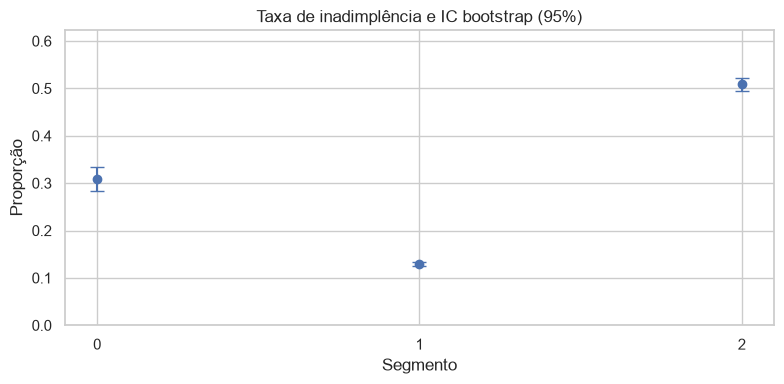

In [11]:
rng = np.random.default_rng(RANDOM_STATE)
intervalos = []

for segmento, grupo in df.groupby("segmento", sort=True):
    valores = grupo["inadimplente"].to_numpy()
    n = len(valores)
    taxas_bootstrap = rng.binomial(n, valores.mean(), size=N_BOOTSTRAP) / n
    li, ls = np.percentile(taxas_bootstrap, [2.5, 97.5])
    intervalos.append({
        "segmento": segmento,
        "clientes": n,
        "taxa": valores.mean(),
        "ic_inferior": li,
        "ic_superior": ls,
    })

ic = pd.DataFrame(intervalos).sort_values("segmento")
display(ic.assign(
    taxa_pct=(ic["taxa"] * 100).round(2),
    inferior_pct=(ic["ic_inferior"] * 100).round(2),
    superior_pct=(ic["ic_superior"] * 100).round(2),
))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(ic))
ax.errorbar(
    x, ic["taxa"],
    yerr=[ic["taxa"] - ic["ic_inferior"], ic["ic_superior"] - ic["taxa"]],
    fmt="o", capsize=5,
)
ax.set_xticks(x, labels=ic["segmento"].astype(str))
ax.set(title="Taxa de inadimplência e IC bootstrap (95%)", xlabel="Segmento", ylabel="Proporção")
ax.set_ylim(0, min(1, ic["ic_superior"].max() + 0.1))
plt.tight_layout()
plt.savefig(FIGURAS / "05_intervalos_bootstrap.png", dpi=140)
plt.show()

## 5. Comparação entre os segmentos de menor e maior risco

Estimamos a diferença absoluta de taxas entre o maior e o menor valor observado. A escolha dos extremos foi feita olhando os dados; portanto, o intervalo é **exploratório** e não deve ser apresentado como teste confirmatório pré-registrado.

In [12]:
menor = int(resumo.loc[resumo["taxa"].idxmin(), "segmento"])
maior = int(resumo.loc[resumo["taxa"].idxmax(), "segmento"])

amostra_menor = df.loc[df["segmento"] == menor, "inadimplente"].to_numpy()
amostra_maior = df.loc[df["segmento"] == maior, "inadimplente"].to_numpy()

rng_diff = np.random.default_rng(RANDOM_STATE + 1)
taxas_menor = rng_diff.binomial(len(amostra_menor), amostra_menor.mean(), N_BOOTSTRAP) / len(amostra_menor)
taxas_maior = rng_diff.binomial(len(amostra_maior), amostra_maior.mean(), N_BOOTSTRAP) / len(amostra_maior)
diferencas = taxas_maior - taxas_menor
limite_inf, limite_sup = np.percentile(diferencas, [2.5, 97.5])
dif_obs = amostra_maior.mean() - amostra_menor.mean()

print(f"Segmentos: maior risco = {maior}; menor risco = {menor}")
print(f"Diferença observada: {dif_obs * 100:.2f} pontos percentuais")
print(f"IC bootstrap de 95%: [{limite_inf * 100:.2f}, {limite_sup * 100:.2f}] p.p.")

Segmentos: maior risco = 2; menor risco = 1
Diferença observada: 37.89 pontos percentuais
IC bootstrap de 95%: [36.48, 39.37] p.p.


## 6. Limite de crédito e inadimplência

O teste de Mann–Whitney compara a distribuição dos limites de crédito entre clientes adimplentes e inadimplentes. A variável é assimétrica, então usamos um teste não paramétrico. Diferença estatística não implica que o limite de crédito cause inadimplência.

Mediana — adimplentes: 150,000.00
Mediana — inadimplentes: 90,000.00
Mann–Whitney U: 60950388
p-valor: 3.659e-143
Resultado (5%): rejeitamos H0


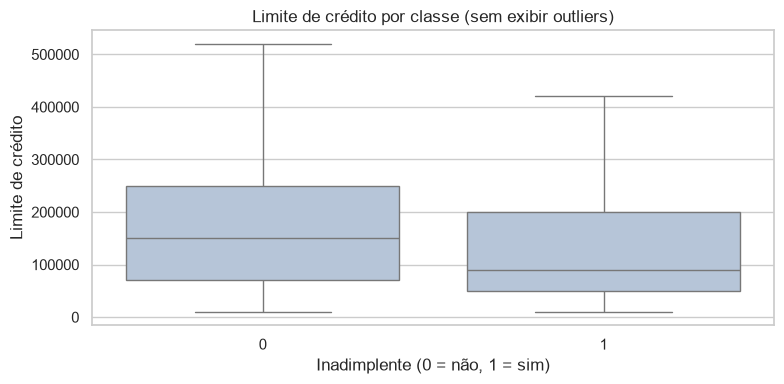

In [13]:
limite_0 = df.loc[df["inadimplente"] == 0, "limite_credito"].to_numpy()
limite_1 = df.loc[df["inadimplente"] == 1, "limite_credito"].to_numpy()

estatistica_u, p_mw = mannwhitneyu(limite_0, limite_1, alternative="two-sided", method="asymptotic")

print("Mediana — adimplentes:", f"{np.median(limite_0):,.2f}")
print("Mediana — inadimplentes:", f"{np.median(limite_1):,.2f}")
print(f"Mann–Whitney U: {estatistica_u:.0f}")
print(f"p-valor: {p_mw:.3e}")
print("Resultado (5%):", "rejeitamos H0" if p_mw < 0.05 else "não rejeitamos H0")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="inadimplente", y="limite_credito", showfliers=False, ax=ax, color="lightsteelblue")
ax.set(title="Limite de crédito por classe (sem exibir outliers)", xlabel="Inadimplente (0 = não, 1 = sim)", ylabel="Limite de crédito")
plt.tight_layout()
plt.savefig(FIGURAS / "05_limite_credito_classes.png", dpi=140)
plt.show()

## 7. Exportação

Salvamos as tabelas e os resultados para o README e o dashboard. Os números só serão comentados na conclusão após executar as células com o dataset real.

In [14]:
DESTINO = ROOT / "reports" / "estatistica"
DESTINO.mkdir(parents=True, exist_ok=True)

resumo.to_csv(DESTINO / "taxas_segmentos.csv", index=False)
ic.to_csv(DESTINO / "intervalos_segmentos.csv", index=False)

metricas = {
    "n_registros_treino": int(len(df)),
    "qui_quadrado": float(chi2),
    "p_qui_quadrado": float(p_valor),
    "v_cramer": float(v_cramer),
    "segmento_menor_risco": menor,
    "segmento_maior_risco": maior,
    "diferenca_taxas": float(dif_obs),
    "ic_diferenca_95": [float(limite_inf), float(limite_sup)],
    "mann_whitney_u": float(estatistica_u),
    "p_mann_whitney": float(p_mw),
    "bootstrap_repeticoes": N_BOOTSTRAP,
    "random_state": RANDOM_STATE,
}

(DESTINO / "metricas.json").write_text(
    json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Resultados salvos em reports/estatistica/ e reports/figures/.")

Resultados salvos em reports/estatistica/ e reports/figures/.


## 8. Conclusão

*Preencher depois de executar com os arquivos reais do notebook 02.*

Registrar aqui: resultado do qui-quadrado, V de Cramér, intervalos de confiança por segmento, diferença entre segmentos e resultado do Mann–Whitney.

**Limitações:** testes observacionais não demonstram causalidade; os segmentos foram formados com informações financeiras relacionadas ao risco; intervalos bootstrap assumem observações independentes e não levam em conta toda a incerteza da seleção de variáveis e ajuste do K-Means. A base tem dados históricos de Taiwan e não representa diretamente a população brasileira.